In [1]:
import ants
import nibabel as nib
import numpy as np
import pandas as pd
import nilearn
from nilearn import surface
import os
from brainstat.datasets import fetch_mask, fetch_template_surface
from brainspace.plotting import plot_hemispheres
import scipy.stats as stats

pial_left, pial_right = fetch_template_surface("fslr32k",join=False)
mask = fetch_mask("fslr32k")

In [2]:
# Calculate Mutual Information using ANTsPy
def mutual_information(img1, img2, bins=32):
    """Calculate mutual information between two images using ANTsPy."""
    if img1 is None or img2 is None:
        return None
    # Convert numpy arrays to ANTs images
    img1_ants = ants.from_numpy(img1.astype(np.float32))
    img2_ants = ants.from_numpy(img2.astype(np.float32))
    # Calculate mutual information directly with ANTsPy
    return ants.image_mutual_information(img1_ants, img2_ants)

# Generate mean and stdev maps
def mean_std_gen(L_surf,R_surf,mask=None):
    mean = np.hstack((
        np.mean(L_surf,axis=0),
        np.mean(R_surf,axis=0)
    ))

    if mask is not None:
        mean[~mask] = np.nan
    
    std = np.hstack((
        np.std(L_surf,axis=0),
        np.std(R_surf,axis=0)
    ))
    if mask is not None:
        std[~mask] = np.nan
    
    return np.vstack((mean,std))

# Generate cohen's D map
from scipy import stats
from statsmodels.stats.multitest import multipletests

def cohenD_gen(L_surf,R_surf,HC_L_surf,HC_R_surf,mask):
    HC_mean = np.hstack((
        np.mean(HC_L_surf,axis=0),
        np.mean(HC_R_surf,axis=0)
    ))
    
    HC_std = np.hstack((
        np.std(HC_L_surf,axis=0),
        np.std(HC_R_surf,axis=0)
    ))
    
    n1 = HC_mean.shape[0]
    
    test_mean = np.hstack((
        np.mean(L_surf,axis=0),
        np.mean(R_surf,axis=0)
    ))
    test_std = np.hstack((
        np.std(L_surf,axis=0),
        np.std(R_surf,axis=0)
    ))
    n2 = test_mean.shape[0]
    
    pooled_std = np.sqrt(((n1 - 1) * HC_std**2 + (n2 - 1) * test_std**2) / (n1 + n2 - 2))
    
    cohens_d = (test_mean - HC_mean) / pooled_std

    # tstats,pvals = stats.ttest_ind(np.hstack((L_surf,R_surf)),
    #                                 np.hstack((HC_L_surf,HC_R_surf)),
    #                                 axis=0,
    #                             equal_var=False)  
    
    # # Apply False Discovery Rate (FDR) correction at a 5% significance level
    # reject_null, corrected_pvals, _, _ = multipletests(pvals, 
    #                                                     alpha=0.05, 
    #                                                     method='fdr_bh')                        
    
    # to_return = np.vstack((tstats,corrected_pvals,cohens_d))
    
    to_return = cohens_d
    to_return[~mask] = np.nan
    
    return to_return

def hipp_cohenD_gen(L_surf,R_surf,HC_L_surf,HC_R_surf):
    HC_mean = np.hstack((
        np.expand_dims(np.mean(HC_L_surf,axis=0),axis=1),
        np.expand_dims(np.mean(HC_R_surf,axis=0),axis=1)
    ))

    HC_std = np.hstack((
        np.expand_dims(np.std(HC_L_surf,axis=0),axis=1),
        np.expand_dims(np.std(HC_R_surf,axis=0),axis=1)
    ))
    
    n1 = HC_mean.shape[0]

    test_mean = np.hstack((
        np.expand_dims(np.mean(L_surf,axis=0),axis=1),
        np.expand_dims(np.mean(R_surf,axis=0),axis=1)
    ))

    test_std = np.hstack((
        np.expand_dims(np.std(L_surf,axis=0),axis=1),
        np.expand_dims(np.std(R_surf,axis=0),axis=1)
    ))

    n2 = test_mean.shape[0]
    
    pooled_std = np.sqrt(((n1 - 1) * HC_std**2 + (n2 - 1) * test_std**2) / (n1 + n2 - 2))
    
    cohens_d = (test_mean - HC_mean) / pooled_std

    # tstats,pvals = stats.ttest_ind(np.hstack((L_surf,R_surf)),
    #                                 np.hstack((HC_L_surf,HC_R_surf)),
    #                                 axis=0,
    #                             equal_var=False)  
    
    # # Apply False Discovery Rate (FDR) correction at a 5% significance level
    # reject_null, corrected_pvals, _, _ = multipletests(pvals, 
    #                                                     alpha=0.05, 
    #                                                     method='fdr_bh')                        
    
    # to_return = np.vstack((tstats,corrected_pvals,cohens_d))
    
    to_return = cohens_d
    
    return to_return

# Generate Asymmetry Index map
# from enigmatoolbox.plotting import plot_subcortical

def AI_gen(surf_L, surf_R):
    surf_L_mean = np.mean(surf_L, axis=0)
    surf_R_mean = np.mean(surf_R, axis=0)

    AI = (surf_L_mean - surf_R_mean) / ((surf_L_mean + surf_R_mean) / 2)

    return np.hstack((AI,AI))

# Generate HC map
import hippomaps as hm

def HC_gen(hipp_surf_L,hipp_surf_R):
    to_plot = np.hstack((np.expand_dims(np.mean(hipp_surf_L,axis=0),axis=1),np.expand_dims(np.mean(hipp_surf_R,axis=0),axis=1)))
    return to_plot

def HC_gen_std(hipp_surf_L,hipp_surf_R):
    to_plot = np.hstack((np.expand_dims(np.std(hipp_surf_L,axis=0),axis=1),np.expand_dims(np.std(hipp_surf_R,axis=0),axis=1)))
    return to_plot

# IceAmp
import numpy as np
import cmocean
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

n = 128
fade_frac = 0.35  # fraction of each half that fades toward gray

ice = cmocean.cm.ice
amp = cmocean.cm.amp
gray40 = np.array(mcolors.to_rgb("#CCCCCC"))

# crop the black end off ice
ice_colors = ice(np.linspace(0.25, 1.0, n))[:, :3]
amp_colors = amp(np.linspace(0.0, 1.0, n))[:, :3]

# optional: smoothstep easing instead of linear, for a gentler (C1) blend
def smoothstep(w):
    return w * w * (3 - 2 * w)

n_fade = int(n * fade_frac)

# blend the END of ice_colors toward gray40
w = smoothstep(np.linspace(0, 1, n_fade))[:, None]
ice_colors[-n_fade:] = (1 - w) * ice_colors[-n_fade:] + w * gray40

# blend the START of amp_colors FROM gray40
w = smoothstep(np.linspace(0, 1, n_fade))[:, None]
amp_colors[:n_fade] = (1 - w) * gray40 + w * amp_colors[:n_fade]

colors = np.vstack([ice_colors, amp_colors])
IceAmp = mcolors.LinearSegmentedColormap.from_list("IceAmp", colors, N=256)

# preview
# fig, ax = plt.subplots(figsize=(6, 1))
# ax.imshow(np.linspace(-1, 1, 256).reshape(1, -1), cmap=IceAmp, aspect="auto")
# ax.set_axis_off()
# plt.show()


def plot_hemi(T,group,L_surf_list,R_surf_list,mask,cmap_max,cohenD=False):
    idx = np.where(T["Group"] == group)[0]

    surf_L = [L_surf_list[i] for i in idx]
    surf_R = [R_surf_list[i] for i in idx]

    to_plot = mean_std_gen(surf_L,surf_R,mask)
    size=(900,400)
    cmap_list = ["viridis","Reds"]
    color_range=[(0,cmap_max),(0,0.25)]
    
    if cohenD is True:
        idx = np.where(T["Group"] == "CN")[0]

        HC_surf_L = [L_surf_list[i] for i in idx]
        HC_surf_R = [R_surf_list[i] for i in idx]
        to_plot = np.vstack((
            to_plot,
            cohenD_gen(surf_L,surf_R,HC_surf_L,HC_surf_R,mask)
        ))
        cmap_list = ["viridis","Reds",IceAmp]
        size=(900,600)
        color_range=[(0,cmap_max),(0,0.25),(-3,3)]

    return plot_hemispheres(pial_left, pial_right,to_plot,
        color_bar=True,
        embed_nb=True,
        transparent_bg=True,
        zoom=1.25,
        color_range=color_range,
        size=size,
        nan_color=(1, 1, 1, 1),
        cmap=cmap_list)

def plot_HC(T, group, L_surf_list, R_surf_list, cmap_max=1.25, map="mean"):
    idx = np.where(T["Group"] == group)[0]

    surf_L = [L_surf_list[i] for i in idx]
    surf_R = [R_surf_list[i] for i in idx]

    if map == "mean":
        data = HC_gen(surf_L, surf_R)
        cmap = "viridis"
        color_range = (0, cmap_max)
    elif map == "std":
        data = HC_gen_std(surf_L, surf_R)
        cmap = "Reds"
        color_range = (0, cmap_max)
    elif map == "cohenD":
        idx = np.where(T["Group"] == "CN")[0]

        HC_surf_L = [L_surf_list[i] for i in idx]
        HC_surf_R = [R_surf_list[i] for i in idx]
        data = hipp_cohenD_gen(surf_L, surf_R, HC_surf_L, HC_surf_R)
        cmap = IceAmp
        color_range = (-3, 3)
    else:
        raise ValueError("map must be 'mean' or 'std'")

    return hm.plotting.surfplot_canonical_foldunfold(
        data,
        color_bar=True,
        color_range=color_range,
        hemis=['L', 'R'],
        den='2mm',
        labels=['hipp'],
        embed_nb=True,
        transparent_bg=True,
        tighten_cwindow=True,
        cmap=cmap,
        size=[350, 300]
    )

# AV45

In [3]:
T_AV45 = pd.read_csv("/host/verges/tank/data/jack/AV45/BIDS_ADNI_AV45/AV45_shortlist_demographics.csv")
BIDS_AV45 = '/host/verges/tank/data/jack/AV45/BIDS_ADNI_AV45'

AV45_L_surf = []
AV45_R_surf = []
AV45_L_HCsurf = []
AV45_R_HCsurf = []

MICA_PET_dir = f"{BIDS_AV45}/derivatives/MICA-PET_v.beta.0.1"

for subj in T_AV45.Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    AV45_L_surf.append(nilearn.surface.load_surf_data(L_file))
    AV45_R_surf.append(nilearn.surface.load_surf_data(R_file))

    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-hipp_den-2mm_label-midthickness_pvc-IY_ref-composite_trc-AV45_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-hipp_den-2mm_label-midthickness_pvc-IY_ref-composite_trc-AV45_pet.func.gii")
    AV45_L_HCsurf.append(nilearn.surface.load_surf_data(L_file))
    AV45_R_HCsurf.append(nilearn.surface.load_surf_data(R_file))



In [7]:
idx = np.where(T_AV45["Group"] == "CN")[0]

HC_AV45_surf_L = [AV45_L_surf[i] for i in idx]
HC_AV45_surf_R = [AV45_R_surf[i] for i in idx]

HC_AV45_surf = np.hstack((HC_AV45_surf_L, HC_AV45_surf_R))

np.savetxt("/host/verges/tank/data/jack/micapet/resources/reference/referenceset_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.csv", HC_AV45_surf, delimiter=",")


## CN

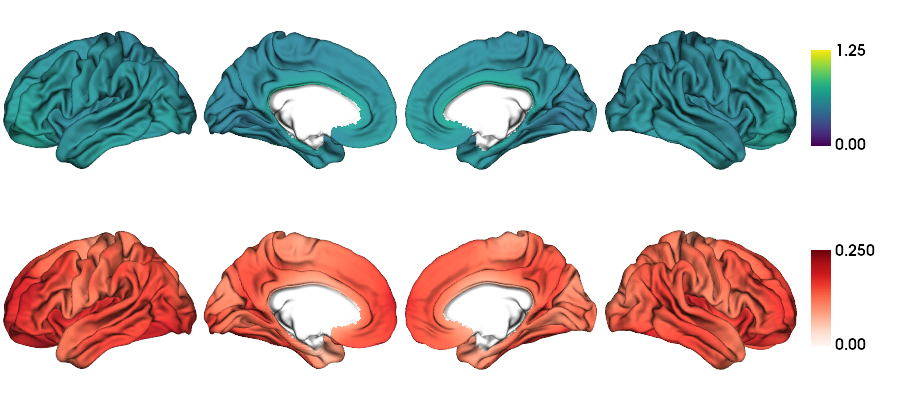

In [5]:
plot_hemi(T_AV45,"CN",AV45_L_surf,AV45_R_surf,mask,1.25)

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


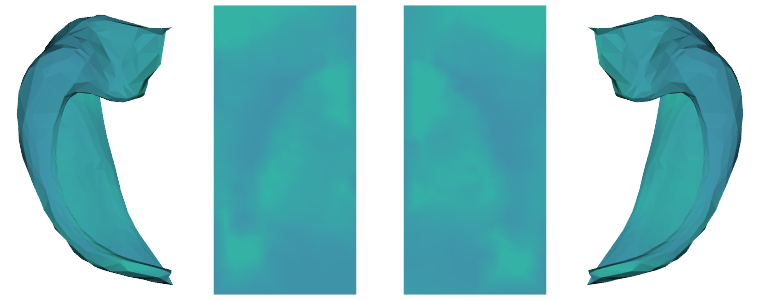

In [7]:
plot_HC(T_AV45, "CN", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=1.25, map="mean")

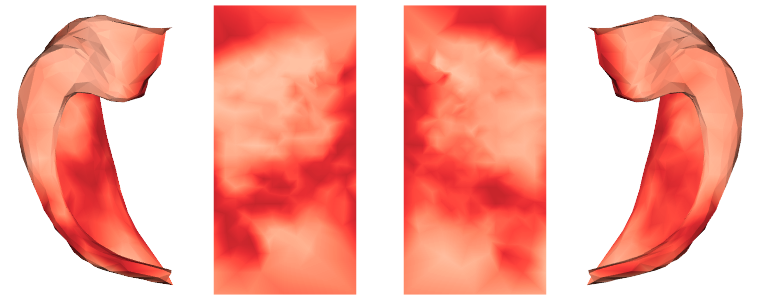

In [8]:
plot_HC(T_AV45,"CN",AV45_L_HCsurf,AV45_R_HCsurf,cmap_max=.25,map="std")

## MCI

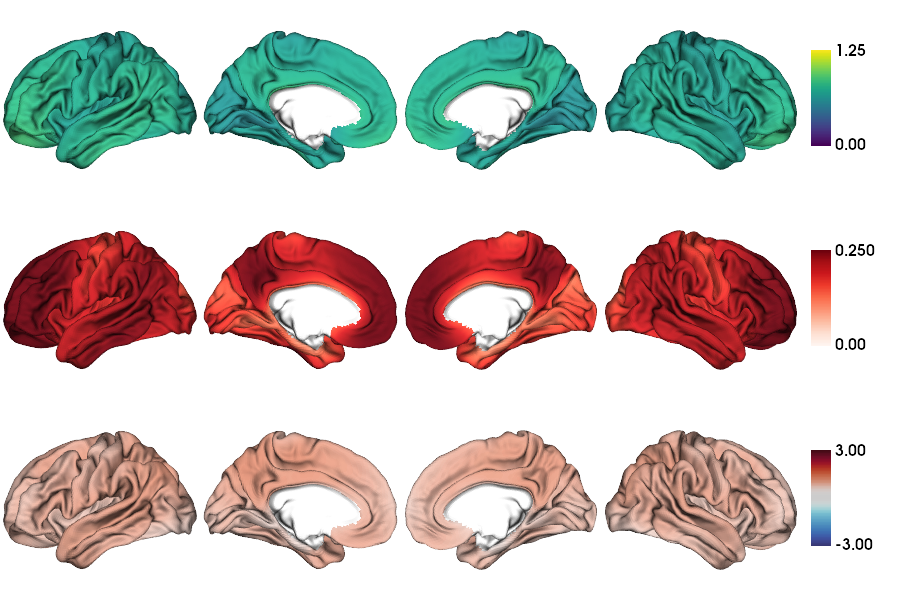

In [ ]:
plot_hemi(T_AV45,"MCI",AV45_L_surf,AV45_R_surf,mask,1.25,cohenD=True)

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


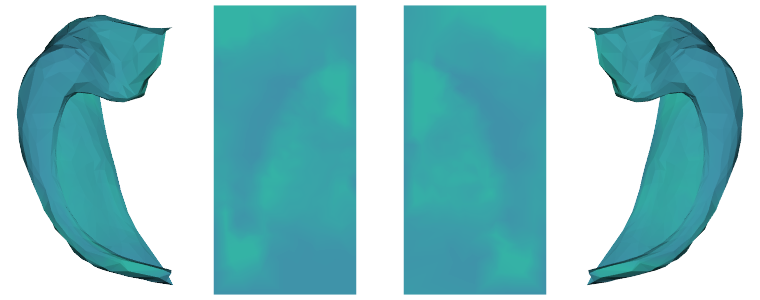

In [ ]:
plot_HC(T_AV45, "MCI", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=1.25, map="mean")

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


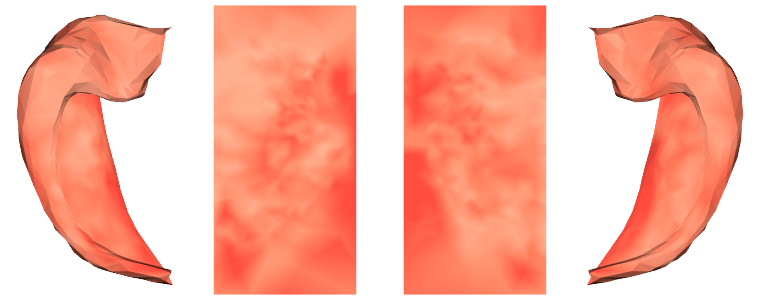

In [6]:
plot_HC(T_AV45, "MCI", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=.25, map="std")

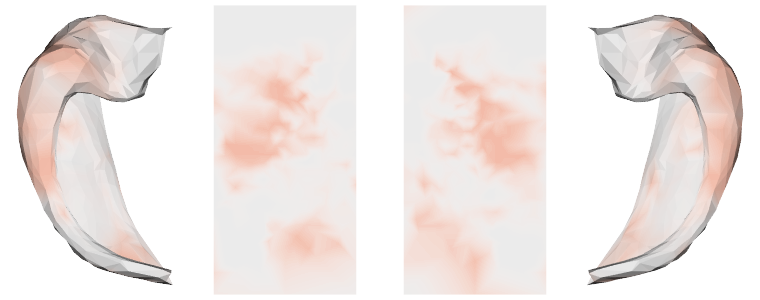

In [7]:
plot_HC(T_AV45, "MCI", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=.25, map="cohenD")

## AD

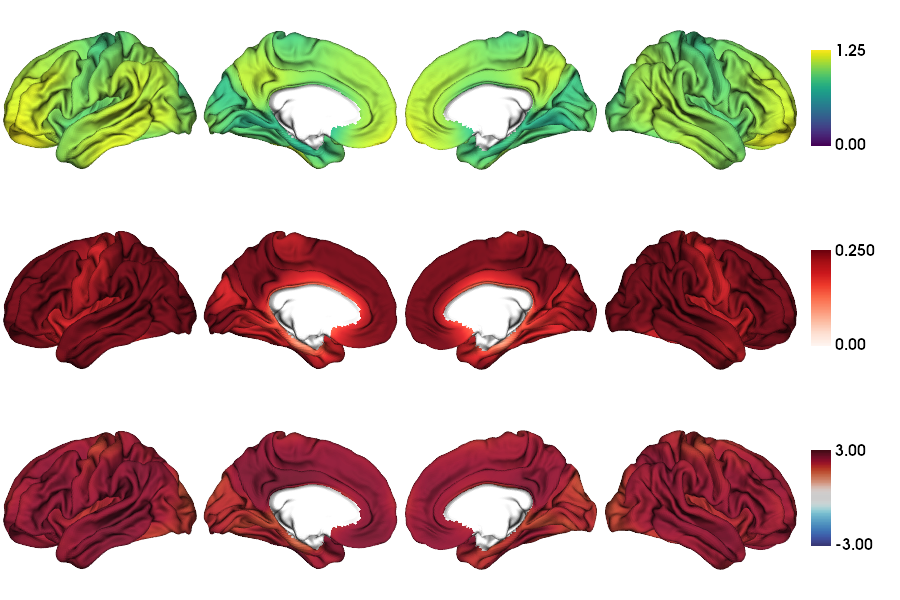

In [8]:
plot_hemi(T_AV45,"AD",AV45_L_surf,AV45_R_surf,mask,1.25,cohenD=True)

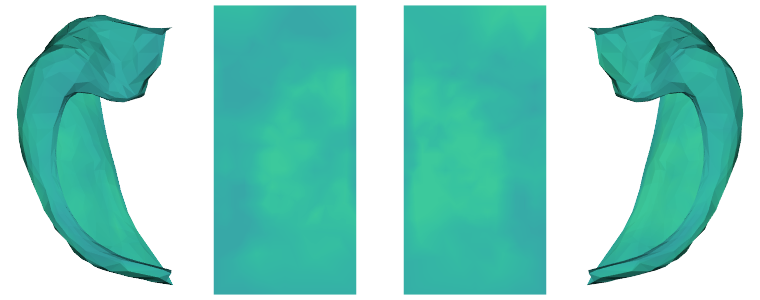

In [9]:
plot_HC(T_AV45, "AD", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=1.25, map="mean")

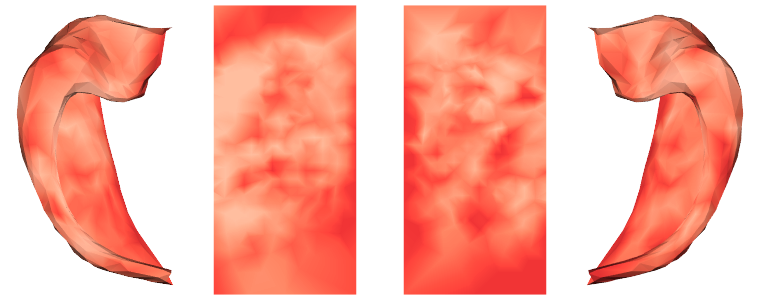

In [11]:
plot_HC(T_AV45, "AD", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=.25, map="std")

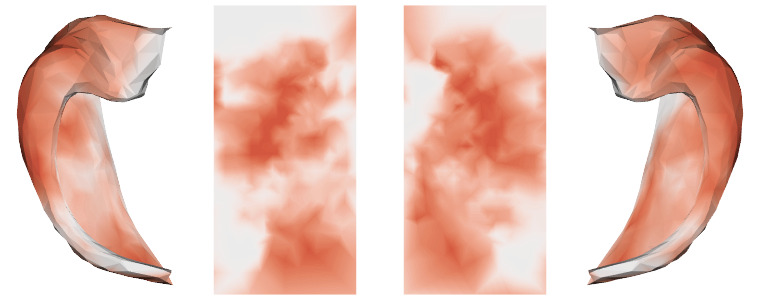

In [12]:
plot_HC(T_AV45, "AD", AV45_L_HCsurf, AV45_R_HCsurf, cmap_max=.25, map="cohenD")

# MK6240

In [14]:
T_MK6240 = pd.read_csv("/host/verges/tank/data/jack/MK6240/BIDS_MK6240_ADNI4/MK6240_shortlist_demographics.csv")
T_MK6240 = T_MK6240[T_MK6240['Subject_short'] != "016S10441"]  # Exclude subject 016S10441
BIDS_MK6240 = '/host/verges/tank/data/jack/MK6240/BIDS_MK6240_ADNI4'
trc='MK6240'
pvc='IY'
ref='cerebellarGM'

MK6240_L_surf = []
MK6240_R_surf = []
MK6240_L_HCsurf = []
MK6240_R_HCsurf = []

MICA_PET_dir = f"{BIDS_MK6240}/derivatives/MICA-PET_v.beta.0.1"

for subj in T_MK6240.Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    MK6240_L_surf.append(nilearn.surface.load_surf_data(L_file))
    MK6240_R_surf.append(nilearn.surface.load_surf_data(R_file))

    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-hipp_den-2mm_label-midthickness_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-hipp_den-2mm_label-midthickness_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.func.gii")
    MK6240_L_HCsurf.append(nilearn.surface.load_surf_data(L_file))
    MK6240_R_HCsurf.append(nilearn.surface.load_surf_data(R_file))

## CN

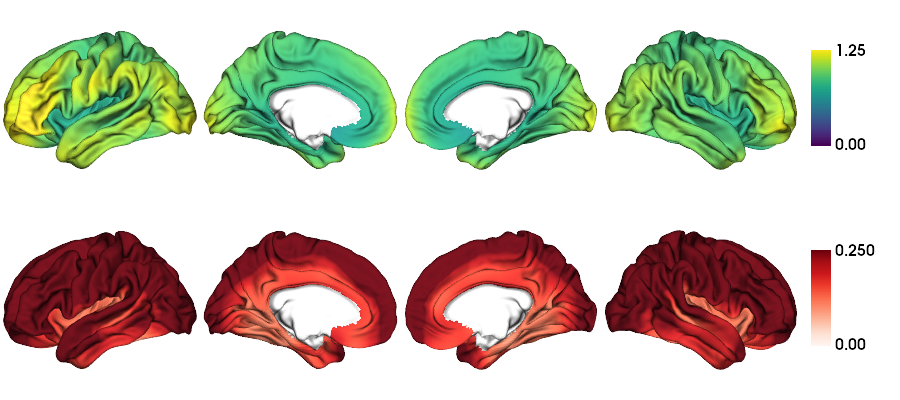

In [15]:
plot_hemi(T_MK6240,"CN",MK6240_L_surf,MK6240_R_surf,mask,1.25)

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


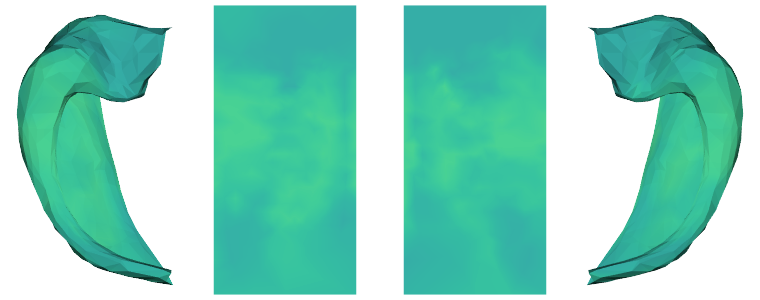

In [16]:
plot_HC(T_MK6240, "CN", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=1.25, map="mean")

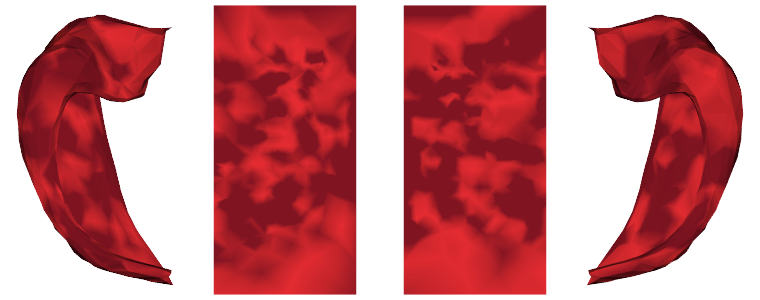

In [18]:
plot_HC(T_MK6240, "CN", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=.25, map="std")

## MCI

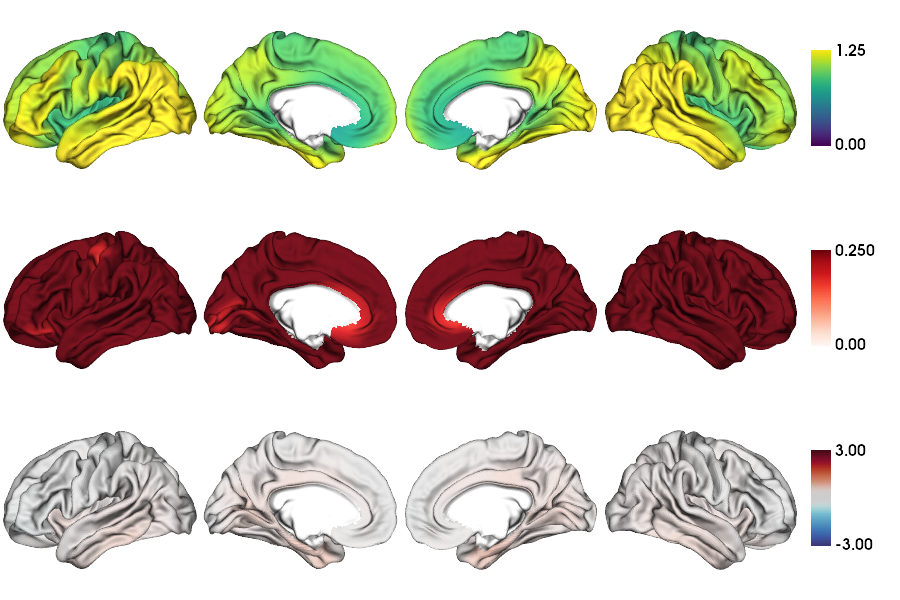

In [19]:
plot_hemi(T_MK6240,"MCI",MK6240_L_surf,MK6240_R_surf,mask,1.25,cohenD=True)

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


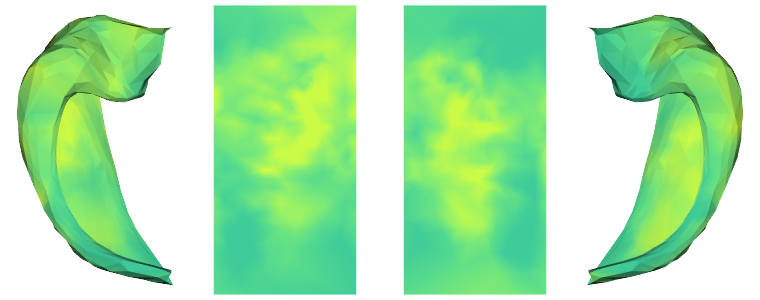

In [20]:
plot_HC(T_MK6240, "MCI", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=1.25, map="mean")

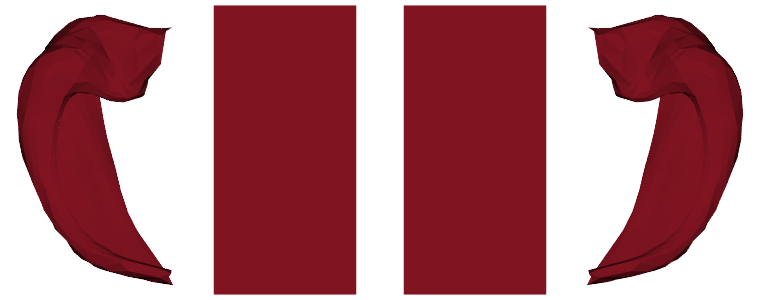

In [22]:
plot_HC(T_MK6240, "MCI", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=.25, map="std")

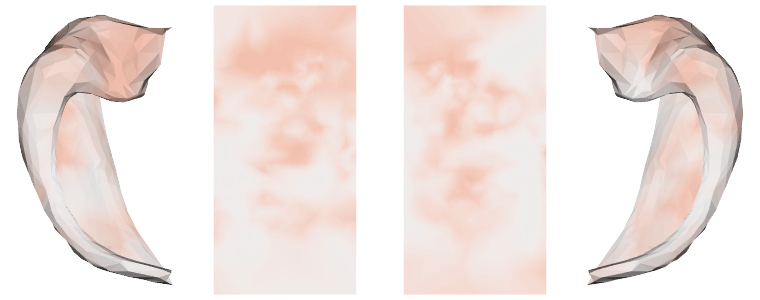

In [23]:
plot_HC(T_MK6240, "MCI", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=.25, map="cohenD")

## AD

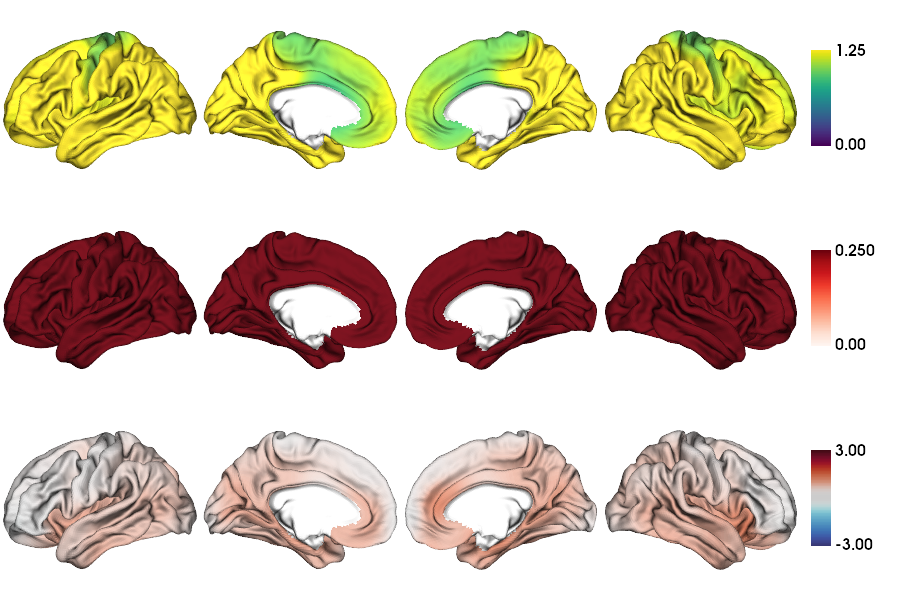

In [24]:
plot_hemi(T_MK6240,"AD",MK6240_L_surf,MK6240_R_surf,mask,1.25,cohenD=True)

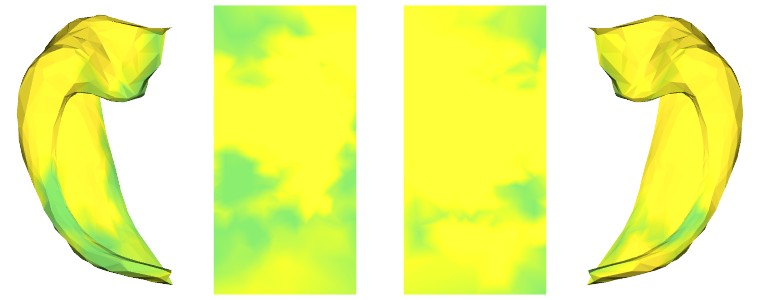

In [25]:
plot_HC(T_MK6240, "AD", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=1.25, map="mean")

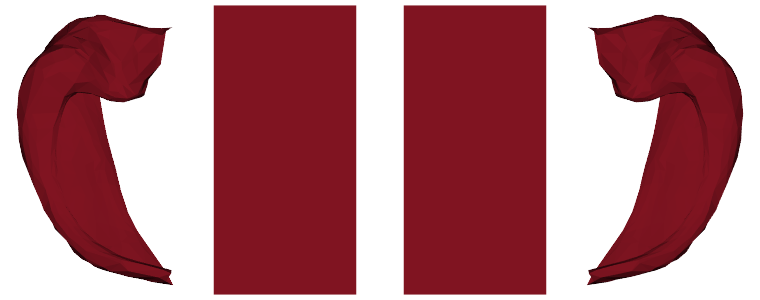

In [27]:
plot_HC(T_MK6240, "AD", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=.25, map="std")

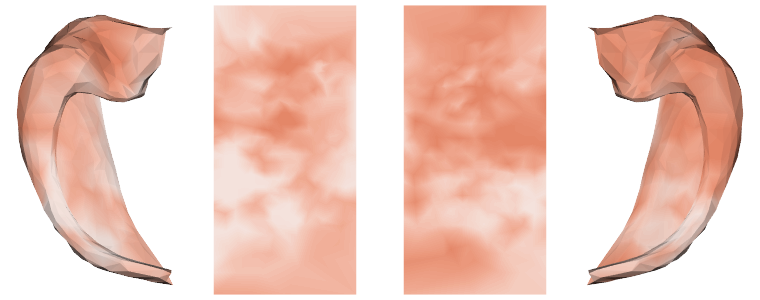

In [28]:
plot_HC(T_MK6240, "AD", MK6240_L_HCsurf, MK6240_R_HCsurf, cmap_max=1.25, map="cohenD")

# FDG

In [29]:
T_FDG = pd.read_csv("/host/verges/tank/data/jack/FDG/BIDS_ADNI1_FDG/FDG_shortlist_demographics.csv")
BIDS_FDG = '/host/verges/tank/data/jack/FDG/BIDS_ADNI1_FDG'
trc='FDG'
pvc='IY'
ref='pons'

FDG_L_surf = []
FDG_R_surf = []
FDG_L_HCsurf = []
FDG_R_HCsurf = []

MICA_PET_dir = f"{BIDS_FDG}/derivatives/MICA-PET_v.beta.0.1"

for subj in T_FDG.Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    FDG_L_surf.append(nilearn.surface.load_surf_data(L_file))
    FDG_R_surf.append(nilearn.surface.load_surf_data(R_file))

    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-hipp_den-2mm_label-midthickness_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-hipp_den-2mm_label-midthickness_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.func.gii")
    FDG_L_HCsurf.append(nilearn.surface.load_surf_data(L_file))
    FDG_R_HCsurf.append(nilearn.surface.load_surf_data(R_file))

## CN

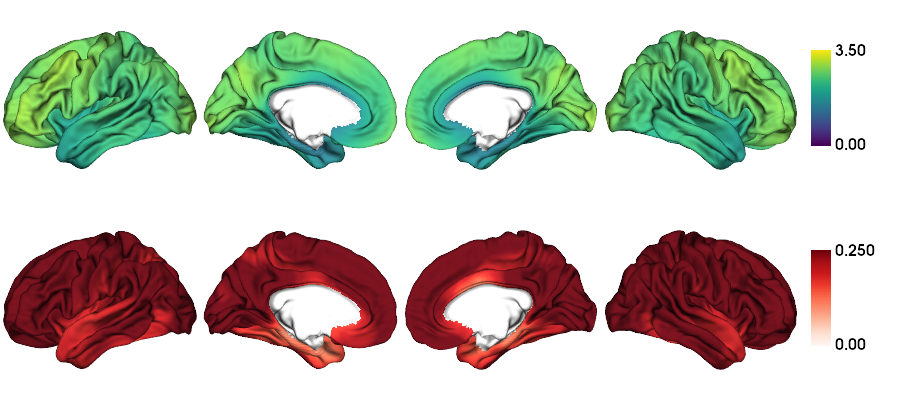

In [30]:
plot_hemi(T_FDG,"CN",FDG_L_surf,FDG_R_surf,mask,3.5)

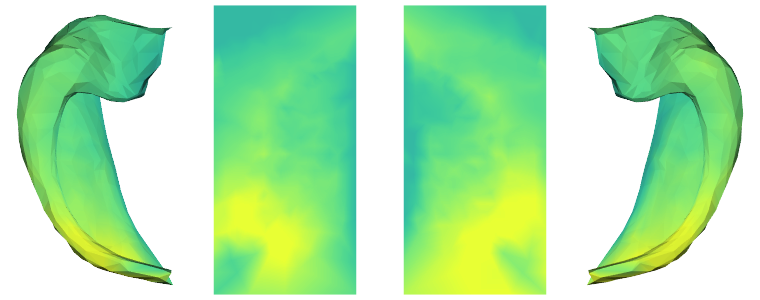

In [32]:
plot_HC(T_FDG, "CN", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=2, map="mean")

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


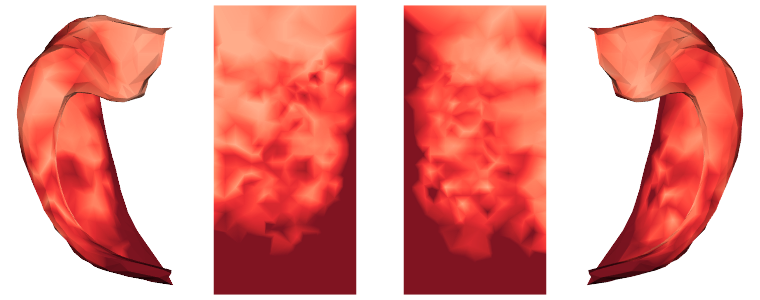

In [34]:
plot_HC(T_FDG, "CN", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=.25, map="std")

## MCI

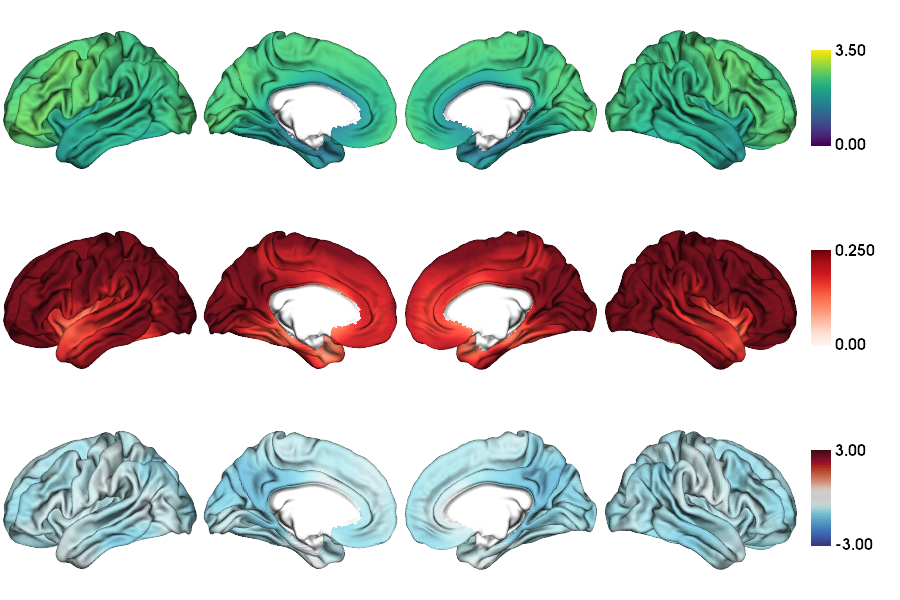

In [35]:
plot_hemi(T_FDG,"MCI",FDG_L_surf,FDG_R_surf,mask,3.5,cohenD=True)

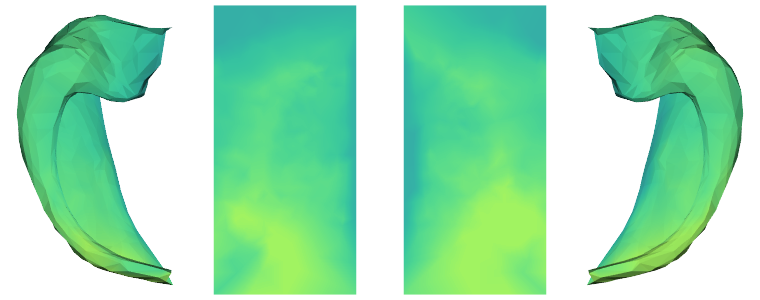

In [36]:
plot_HC(T_FDG, "MCI", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=2, map="mean")

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


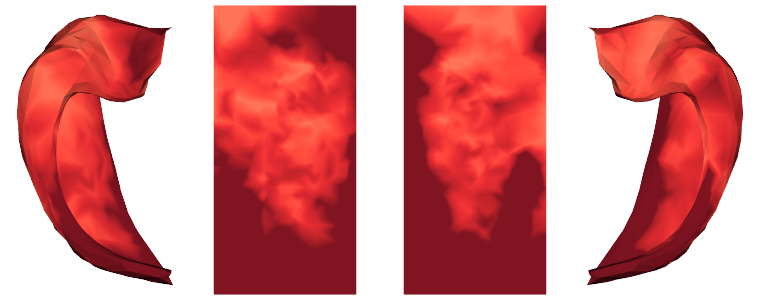

In [38]:
plot_HC(T_FDG, "MCI", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=.25, map="std")

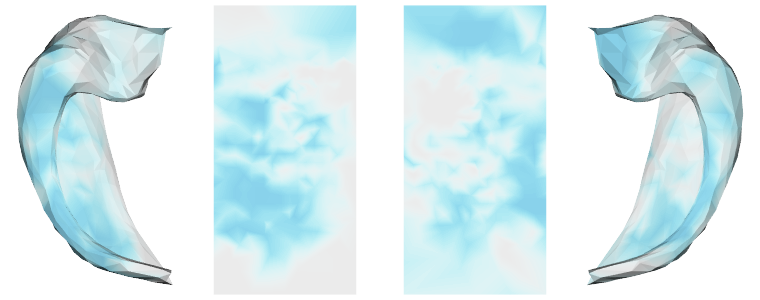

In [39]:
plot_HC(T_FDG, "MCI", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=.25, map="cohenD")

## AD

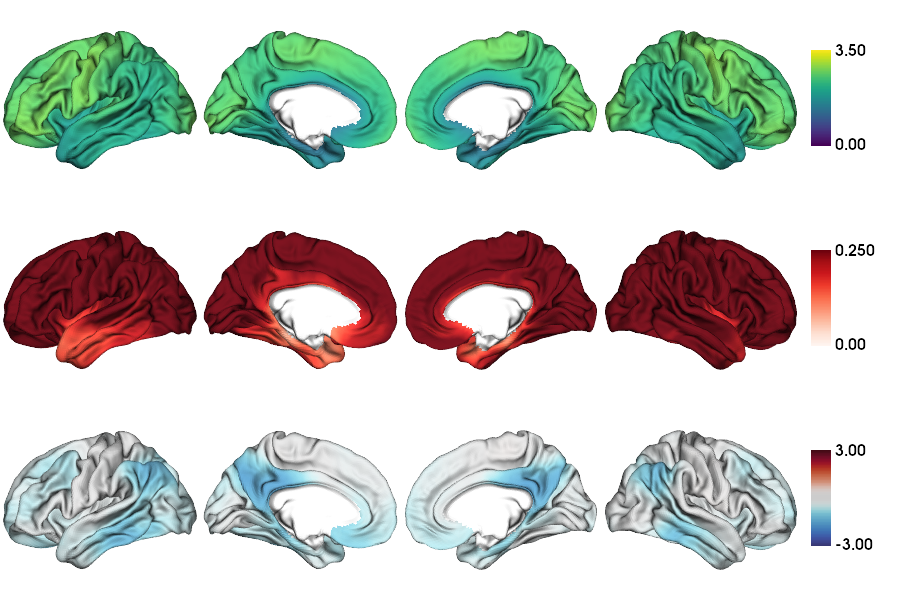

In [40]:
plot_hemi(T_FDG,"AD",FDG_L_surf,FDG_R_surf,mask,3.5,cohenD=True)

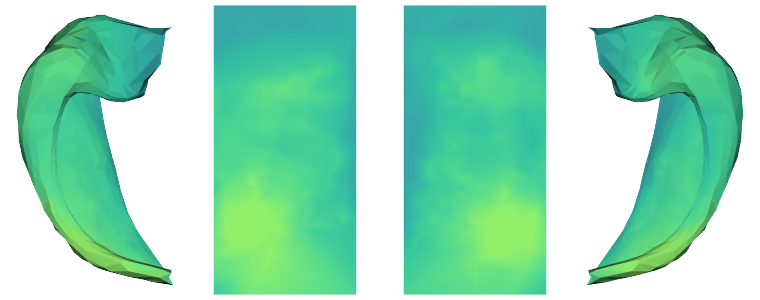

In [41]:
plot_HC(T_FDG, "AD", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=2, map="mean")

/host/fladgate/local_raid/jack/programs/scripts/anaconda3/envs/mica-pet/lib/python3.10/site-packages/brainspace/plotting/base.py:295: UserWarning: Interactive mode requires 'panel'. Setting 'interactive=False'
  warnings.warn("Interactive mode requires 'panel'. "


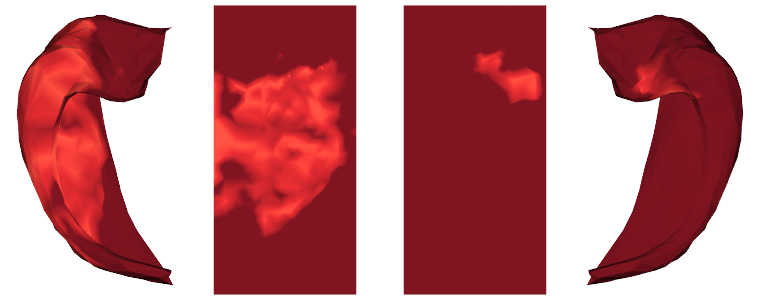

In [42]:
plot_HC(T_FDG, "AD", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=.25, map="std")

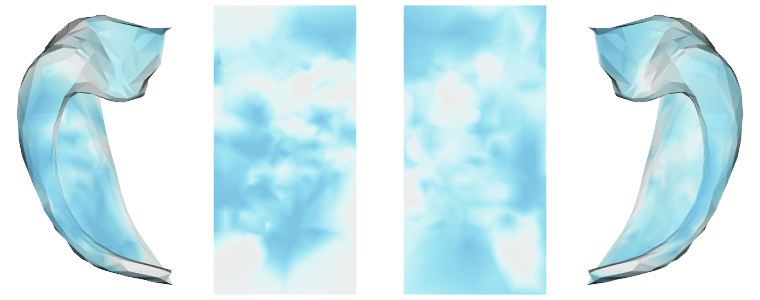

In [43]:
plot_HC(T_FDG, "AD", FDG_L_HCsurf, FDG_R_HCsurf, cmap_max=.25, map="cohenD")

# MI

In [45]:
MNI_img = nib.load('/host/verges/tank/data/jack/micapet/resources/mni_icbm152_t1_tal_nlin_sym_09a.nii.gz').get_fdata()

mi_values = []
mi_values_MNI = []
for subj in T_AV45['Subject_short']:
    img1 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-AV45_pet.nii.gz').get_fdata()
    
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

    img3 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-MNI_pvc-none_ref-none_trc-AV45_pet.nii.gz').get_fdata()
    mi = mutual_information(img3,MNI_img)
    mi_values_MNI.append(mi)

    
T_AV45['Mutual_Information'] = mi_values
T_AV45['Mutual_Information_MNI'] = mi_values_MNI

mi_values = []
mi_values_MNI = []
for subj in T_MK6240['Subject_short']:
    img1 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-MK6240_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

    img3 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-MNI_pvc-none_ref-none_trc-MK6240_pet.nii.gz').get_fdata()
    mi = mutual_information(img3,MNI_img)
    mi_values_MNI.append(mi)

T_MK6240['Mutual_Information'] = mi_values
T_MK6240['Mutual_Information_MNI'] = mi_values_MNI

mi_values = []
mi_values_MNI = []
for subj in T_FDG['Subject_short']:
    img1 = nib.load(f'{BIDS_FDG}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_FDG}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

    img3 = nib.load(f'{BIDS_FDG}/derivatives/MICA-PET_v.beta.0.1/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-MNI_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata()
    mi = mutual_information(img3,MNI_img)
    mi_values_MNI.append(mi)
    
T_FDG['Mutual_Information'] = mi_values
T_FDG['Mutual_Information_MNI'] = mi_values_MNI

#concatenate all three tracer tables
T_concat = pd.concat([T_AV45, T_MK6240, T_FDG], ignore_index=True)

In [47]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
T_concat = T_concat[T_concat['Subject_short'] != "016S10441"]  # Exclude subject 016S10441

# Create grouped bar plot
# plt.figure(figsize=(16, 9))
sns.boxplot(data=T_concat, x="Tracer", y="Mutual_Information", hue="Group", palette="Blues")

plt.title("Linear Coregistration - Mutual Information by Tracer and Group")
plt.xlabel("Tracer")
plt.ylabel("Mutual Information")
plt.tight_layout()
plt.show()

ValueError: Could not interpret value `Tracer` for `x`. An entry with this name does not appear in `data`.

# CERMEP

In [3]:
def plot_CERMEP(pvc,ref):

    surf_L = []
    surf_R = []
    group = "HC"
    trc = "FDG"
    T_FDG_HC = pd.read_csv('/data_/mica3/BIDS_CERMEP-MRXFDG/participants.csv')
    BIDS_FDG_HC = '/data/mica3/BIDS_CERMEP-MRXFDG'
    MICA_PET_dir = f"{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.6_{pvc}_{ref}"
    for subj in T_FDG_HC.participant_id:
    # for subj in T_FDG_HC[T_FDG_HC["Group"] == group].ID:

        subj = subj.removeprefix("sub-")
        L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
        R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
        surf_L.append(nilearn.surface.load_surf_data(L_file))
        surf_R.append(nilearn.surface.load_surf_data(R_file))
        
    FDG_HC_L_surf = surf_L
    FDG_HC_R_surf = surf_R

    to_plot = mean_std_gen(surf_L,surf_R,mask)

    return plot_hemispheres(pial_left, pial_right,to_plot,
                    color_bar=True,
                    embed_nb=True,
                    transparent_bg=True,
                    zoom=1.25,
                    color_range=[(0,4),(0,0.25)],
                    size=(900,400),
                    nan_color=(1, 1, 1, 1),
                    cmap=["viridis","Reds"])

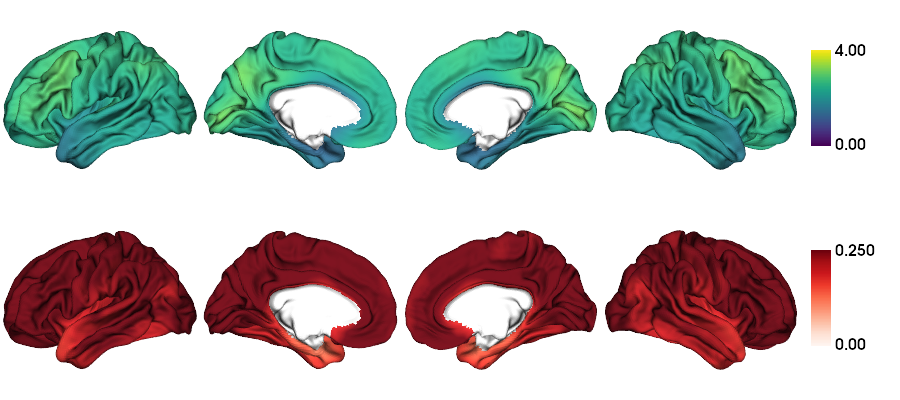

In [21]:
# RBV-FS / pons

plot_CERMEP(pvc="RBV-FS",ref="pons")

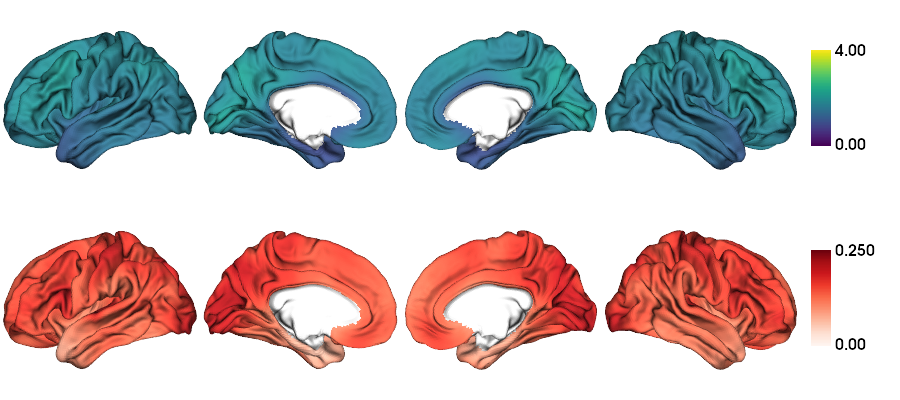

In [22]:
# RBV-FS / cerebellarGM

plot_CERMEP(pvc="RBV-FS",ref="cerebellarGM")

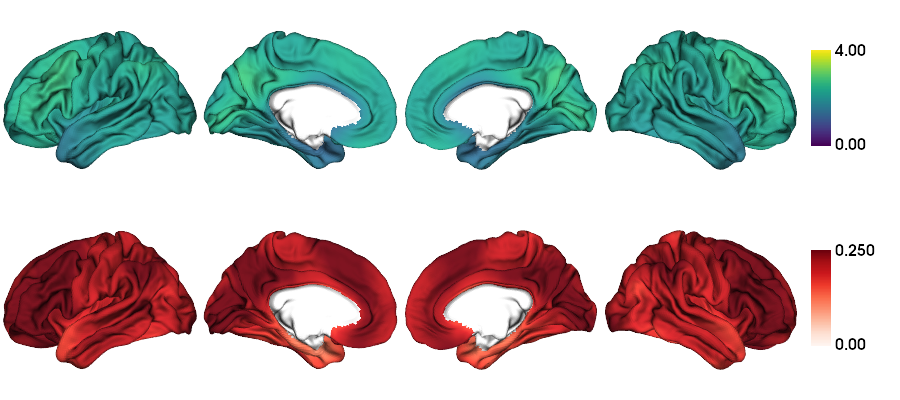

In [23]:
# IY / pons
plot_CERMEP(pvc="IY",ref="pons")

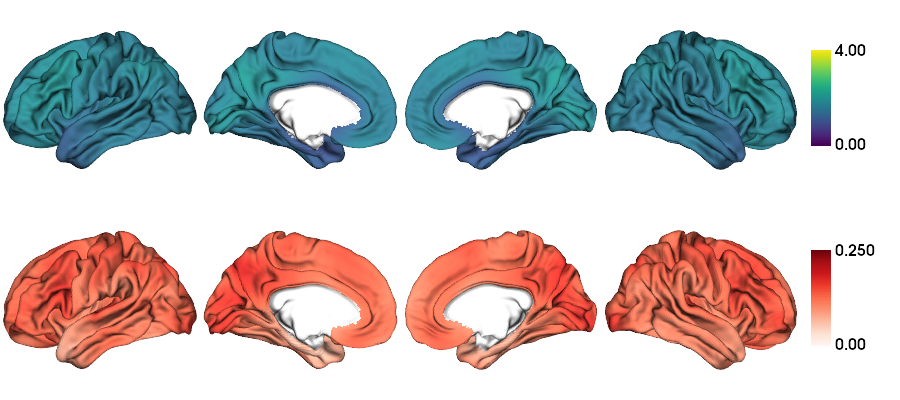

In [24]:
# IY / cerebellarGM
plot_CERMEP(pvc="IY",ref="cerebellarGM")

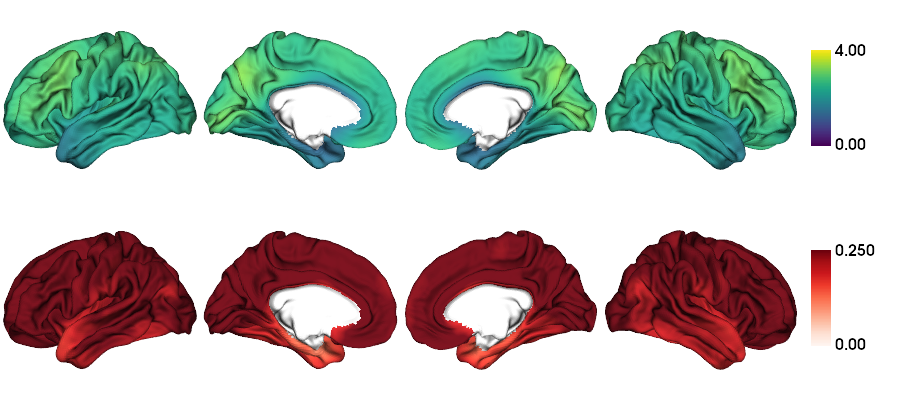

In [25]:
# MG / pons
plot_CERMEP(pvc="MG",ref="pons")

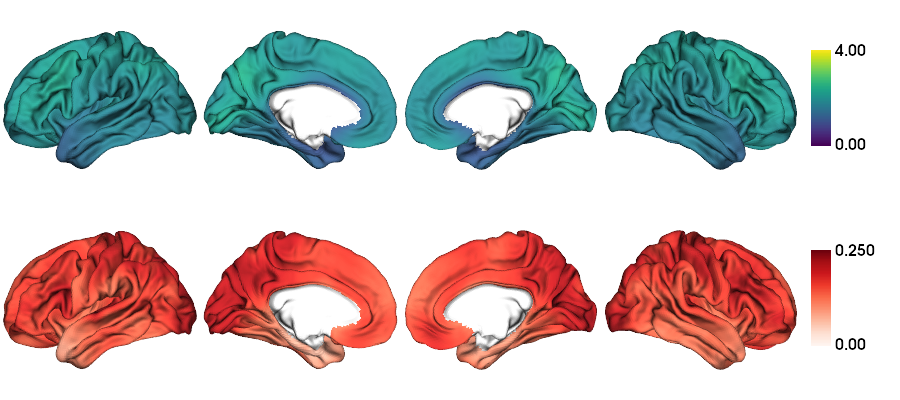

In [26]:
# MG / cerebellarGM
plot_CERMEP(pvc="MG",ref="cerebellarGM")

# BTTH

In [48]:
from pathlib import Path
from typing import List, Union, Tuple, Literal
PathType = Union[str, os.PathLike]
Analysis = Literal["regional", "asymmetry"]

def _load_data_sctx(
    sctx_file: PathType,
    analysis: Analysis,
    threshold: Union[float, None] = None,
    threshold_alpha: float = 0.5,
):
    # Load CSV data
    x = pd.read_csv(sctx_file, header=[0], index_col=None).to_numpy().ravel()
    if threshold is not None:
        x[np.abs(x) < threshold] *= threshold_alpha
    # if analysis == "asymmetry":
    #     print("e")
    # Array of data
    array_16 = np.full(16, np.nan)
    
    if analysis != "asymmetry":
        array_16[0:7] = x[0:7]
        array_16[8:15] = x[7:]
    else:
        array_16[0:7] = (x[0:7]-x[7:])/((x[0:7]+x[7:])/2)
        array_16[8:15] = x[0:7]
        array_16[8:15] = np.nan
    # Fill ventricle slots with 0 (or another default) instead of leaving as NaN
    array_16[7] = np.nan #0.0   # Left ventricle
    array_16[15] = np.nan #0.0  # Right ventricle
    # Map array to vertices of surfaces
    feat_map = map_subcortical_vertices(array_16)
    # Map array to left and right surfaces
    data_lh = feat_map[0:25910]
    data_rh = feat_map[25910:]
    return data_lh, data_rh

def map_subcortical_vertices(x) -> np.ndarray:
    """
    Taken from the ENIGMA toolbox
    https://github.com/MICA-MNI/ENIGMA/blob/master/enigmatoolbox
    Map one value per subcortical area to surface vertices (author:
    @saratheriver)
    Parameters
    ----------
    x:
        Subcortical values with shape = (16,) in the following order:
        L_accumbens, L_amygdala, L_caudate, L_hippocampus, L_pallidun,
        L_putamen, L_thalamus, L_ventricles,
        R_accumbens, R_amygdala, R_caudate, R_hippocampus, R_pallidun,
        R_putamen, R_thalamus, R_ventricles
    zbrains output (the fisrt colum is SubjID):
        'Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput','Lthal',
        'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'
    Returns
    -------
    data :
        Mapped data, shape = (51278,)
    """
    n_vert = [
        867,
        1419,
        3012,
        3784,
        1446,
        4003,
        3726,
        7653,
        838,
        1457,
        3208,
        3742,
        1373,
        3871,
        3699,
        7180,
    ]
    x = np.asarray(x)
    if x.shape == (16,):
        return np.repeat(x, n_vert)
    else:
        raise ValueError("Input data must have 16 values.")

from brainspace.mesh.mesh_io import read_surface
sctx_left = read_surface(f"/host/fladgate/local_raid/jack/FDG/MICA-PET/scripts/surfaces/sctx.L.surf.gii", itype="gii")
sctx_right = read_surface(f"/host/fladgate/local_raid/jack/FDG/MICA-PET/scripts/surfaces/sctx.R.surf.gii", itype="gii")

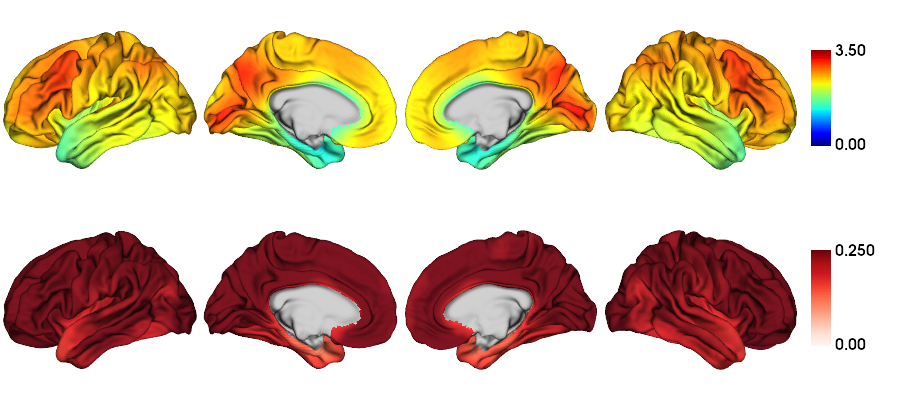

In [ ]:
surf_L = []
surf_R = []
group = "HC"
trc = "FDG"
pvc = "RBV-FS"
ref = "pons"
T_FDG_HC = pd.read_csv('/data_/mica3/BIDS_CERMEP-MRXFDG/participants.csv')
BIDS_FDG_HC = '/data/mica3/BIDS_CERMEP-MRXFDG'
MICA_PET_dir = f"{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.6_{pvc}_{ref}"

# for subj in T_FDG_HC[T_FDG_HC["participant_id"] == group].ID:
for subj in T_FDG_HC.participant_id:
    subj = subj.removeprefix("sub-")
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    
FDG_HC_L_surf = surf_L
FDG_HC_R_surf = surf_R

to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,
    color_bar=True,
    embed_nb=True,
    transparent_bg=True,
    scale_factor=1.25,
    color_range=[(0,3.5),(0,0.25)],
    size=(900,400),
    nan_color=(0.7, 0.7, 0.7, 1),
    cmap=["jet","Reds"])

In [ ]:
hipp_surf_L = []
hipp_surf_R = []
surf_L = []
surf_R = []
sctx_L = []
sctx_R = []
MNI_holder = np.zeros((197,233,189))

T_FDG_BTTH = pd.read_csv("/host/verges/tank/data/mo/BIDS_20251201_TLE_BTTH1/BIDS_BTTH1_demo_old.csv")
T_FDG_BTTH["Group"] = "BTTH"
BIDS_FDG_BTTH = '/host/verges/tank/data/mo/BIDS_20251201_TLE_BTTH1'
T_FDG_BTTH = T_FDG_BTTH[T_FDG_BTTH['ID'] != "sub-PX2401020"]  # Exclude subject PX2401020 -> recheck later

group = "BTTH"
trc = "FDG"
pvc = "RBV-FS"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_BTTH}/derivatives/MICA-PET_v.alpha.0.6"

for subj in T_FDG_BTTH[T_FDG_BTTH["Group"] == group].ID:
    subj = subj.removeprefix('sub-')
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","surf",f"sub-{subj}_ses-pre_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","surf",f"sub-{subj}_ses-pre_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")

    L_hipp_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","surf",f"sub-{subj}_ses-pre_hemi-L_surf-hipp_den-2mm_label-midthickness_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.func.gii")
    R_hipp_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","surf",f"sub-{subj}_ses-pre_hemi-R_surf-hipp_den-2mm_label-midthickness_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.func.gii")

    # sctx_L_data, sctx_R_data = _load_data_sctx(Path(os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","qc",f"sub-{subj}_ses-pre_pvc-{pvc}_ref-{ref}_trc-{trc}_subcortical_means_pet.csv")), analysis="regional")

    sctx_data = np.genfromtxt(os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","qc",f"sub-{subj}_ses-pre_pvc-{pvc}_ref-{ref}_trc-{trc}_subcortical_means_pet.csv"), delimiter=',', skip_header=1)
    sctx_L_data = sctx_data[:7]
    sctx_R_data = sctx_data[7:]

    img = nib.load(os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","pet",f"sub-{subj}_ses-pre_space-MNI_pvc-{pvc}_ref-{ref}_trc-{trc}_pet.nii.gz"))

    if T_FDG_BTTH.loc[T_FDG_BTTH["ID"] == f'sub-{subj}', "Side"].item() == "L":
        surf_L.append(nilearn.surface.load_surf_data(L_file))
        surf_R.append(nilearn.surface.load_surf_data(R_file))

        hipp_surf_L.append(nilearn.surface.load_surf_data(L_hipp_file))
        hipp_surf_R.append(nilearn.surface.load_surf_data(R_hipp_file))

        sctx_L.append(sctx_L_data)
        sctx_R.append(sctx_R_data)

        MNI_holder += img.get_fdata()
    else: 
        surf_R.append(nilearn.surface.load_surf_data(L_file))
        surf_L.append(nilearn.surface.load_surf_data(R_file))

        hipp_surf_R.append(nilearn.surface.load_surf_data(L_hipp_file))
        hipp_surf_L.append(nilearn.surface.load_surf_data(R_hipp_file))

        sctx_R.append(sctx_L_data)
        sctx_L.append(sctx_R_data)

        MNI_holder += np.flip(img.get_fdata(), axis=0)
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,FDG_HC_L_surf,FDG_HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,3.5),(0,0.25),(-1,0)],
                cmap=["jet","Reds","inferno_r"])

# MNI MK6240

In [3]:
# Generate cohen's D map
from scipy import stats
from statsmodels.stats.multitest import multipletests

def cohenD_gen(L_surf,R_surf,HC_L_surf,HC_R_surf,mask):
    HC_mean = np.hstack((
        np.mean(HC_L_surf,axis=0),
        np.mean(HC_R_surf,axis=0)
    ))
    
    HC_std = np.hstack((
        np.std(HC_L_surf,axis=0),
        np.std(HC_R_surf,axis=0)
    ))
    
    n1 = HC_L_surf.shape[0]
    
    test_mean = np.hstack((
        np.mean(L_surf,axis=0),
        np.mean(R_surf,axis=0)
    ))
    test_std = np.hstack((
        np.std(L_surf,axis=0),
        np.std(R_surf,axis=0)
    ))
    n2 = L_surf.shape[0]
    
    pooled_std = np.sqrt(((n1 - 1) * HC_std**2 + (n2 - 1) * test_std**2) / (n1 + n2 - 2))
    
    cohens_d = (test_mean - HC_mean) / pooled_std

    to_return = cohens_d
    to_return[~mask] = np.nan
    
    return to_return

def cohenD_gen_LR(test_surf,HC_surf):
    HC_mean = np.mean(HC_surf,axis=0)

    HC_std = np.std(HC_surf,axis=0)
    
    n1 = HC_surf.shape[0]
    
    test_mean = np.mean(test_surf,axis=0)

    test_std = np.std(test_surf,axis=0)

    n2 = test_surf.shape[0]
    
    pooled_std = np.sqrt(((n1 - 1) * HC_std**2 + (n2 - 1) * test_std**2) / (n1 + n2 - 2))
    
    cohens_d = (test_mean - HC_mean) / pooled_std

    to_return = cohens_d
    # to_return[~mask] = np.nan
    
    return to_return

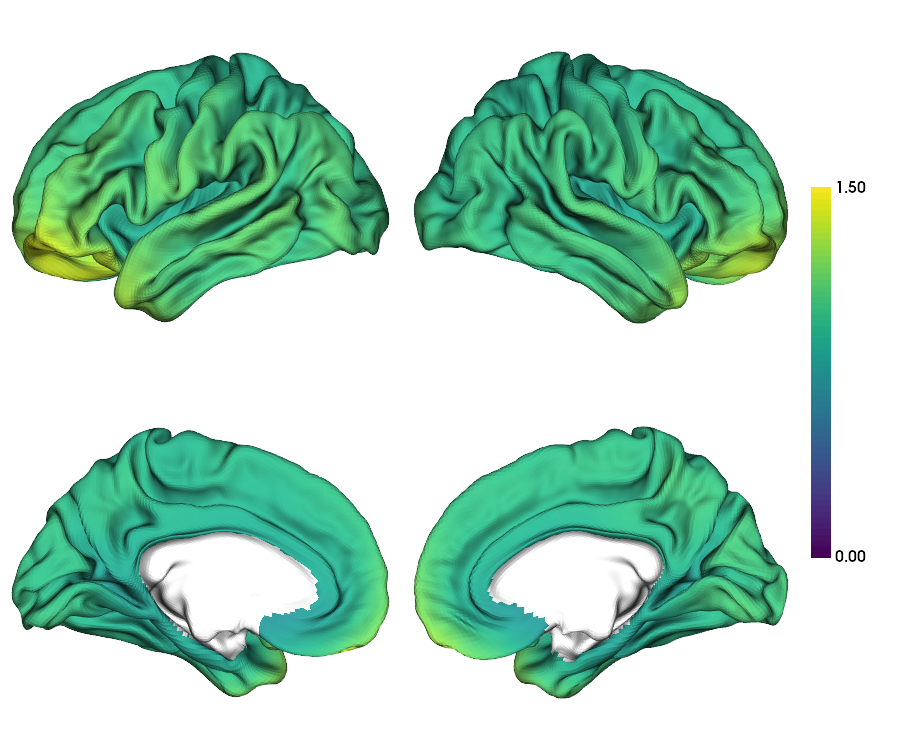

In [4]:
df_HC = pd.read_csv(os.path.join('/host/verges/tank/data/jack/MK6240/BIDS_MK6240_healthy_young', 'MK6240_HC_data.csv'),
    encoding="utf-8",
    encoding_errors="replace")

derivatives_HC = '/host/verges/tank/data/jack/MK6240/BIDS_MK6240_healthy_young/derivatives'
# gather surface data for HC subjects
pvc_method = 'IY'
ref = 'cerebellarGM'
smooth='10mm'
HC_L_gii = []
HC_R_gii = []

for subj in df_HC['ID_orig']:
    tmp_L = nilearn.surface.load_surf_data(os.path.join(derivatives_HC,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii'))

    tmp_R = nilearn.surface.load_surf_data(os.path.join(derivatives_HC,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii'))

    HC_L_gii.append(tmp_L)
    HC_R_gii.append(tmp_R)
    
HC_surf = np.hstack((HC_L_gii, HC_R_gii))

HC_surf[:,~mask] = np.nan

to_plot = np.mean(HC_surf, axis=0)

plot_hemispheres(pial_left, pial_right,to_plot,
                 color_bar=True,
                 embed_nb=True,
                 transparent_bg=True,
                 zoom=1.3,
                 color_range=(0,1.5),
                 size=(900,750),
                 nan_color=(1, 1, 1, 1),
                 cmap="viridis",
                 layout_style='grid',share='both')

In [5]:
df_HC["age"] = df_HC["age_pet_ses1"]
df_HC["code"] = df_HC["ID_orig"]
df_HC

,ID_orig,ID_new,ses,age_pet_ses1,age_round_5,sex,handedness,age,code
0,HC010,s001,2,36,35,M,R,36,HC010
1,HC016,s002,2,29,30,M,R,29,HC016
2,HC052,s003,2,34,35,F,R,34,HC052
3,HC053,s004,2,58,60,M,R,58,HC053
4,HC055,s005,2,34,35,M,R,34,HC055
5,HC062,s006,2,34,35,M,R,34,HC062
6,HC065,s007,2,30,30,M,R,30,HC065
7,HC076,s008,2,30,30,F,L,30,HC076
8,HC088,s009,2,27,25,M,R,27,HC088
9,HC014,s010,1,36,35,M,R,36,HC014


In [6]:
print(f"mean age: {df_HC.age_pet_ses1.mean()}")
print(f"std age: {df_HC.age_pet_ses1.std()}")
print(f"# M: {np.sum(df_HC.sex == 'M')}")
print(f"# F: {np.sum(df_HC.sex == 'F')}")

mean age: 33.97222222222222
std age: 10.437531484602262
# M: 23
# F: 13


In [28]:
# gather surface data for TLE
df_allpt = pd.read_csv(os.path.join('/host/verges/tank/data/jack/MK6240/BIDS_CIHR_July_2026', 'CIHR-BB-JL.csv'),
    encoding="utf-8",
    encoding_errors="replace")
derivatives_allpt = '/host/verges/tank/data/jack/MK6240/BIDS_CIHR_July_2026/derivatives'
df_TLE = df_allpt[df_allpt['code_raulpaper'] == 'Y']

TLE_ips_gii = []
TLE_contra_gii = []

for subj in df_TLE['code']:
    if not os.path.exists(os.path.join(derivatives_allpt,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii')):
        print(f"File for subject {subj} does not exist. Skipping.")
        continue
    if df_TLE.loc[df_TLE['code'] == subj, 'focus'].item() == 'L':
        tmp_ips = nilearn.surface.load_surf_data(os.path.join(derivatives_allpt,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii'))
        tmp_contra = nilearn.surface.load_surf_data(os.path.join(derivatives_allpt,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii'))
        
    else:
        tmp_ips = nilearn.surface.load_surf_data(os.path.join(derivatives_allpt,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii'))
        tmp_contra = nilearn.surface.load_surf_data(os.path.join(derivatives_allpt,'MICA-PET_v.alpha.0.6', f'sub-{subj}', 'ses-01', 'surf', f'sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc_method}_ref-{ref}_smooth-{smooth}_trc-MK6240_pet.func.gii'))
        print(subj)
    TLE_ips_gii.append(tmp_ips)
    TLE_contra_gii.append(tmp_contra) 
TLE_surf = np.hstack((TLE_ips_gii, TLE_contra_gii))
TLE_surf[:,~mask] = np.nan

PX152
PX025
PX044
PX050
PX060
PX067
PX081
PX133
PX142
PX144
PX173
PX216
PX048
PX052
PX071
PX153


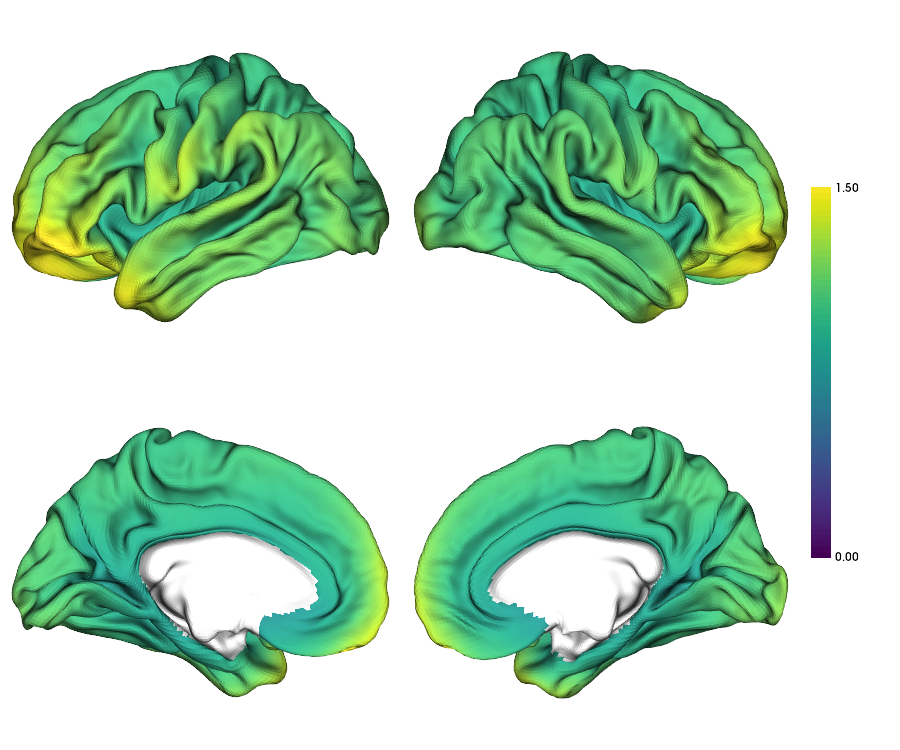

In [33]:
plot_hemispheres(pial_left, pial_right,np.mean(TLE_surf, axis=0),
                 color_bar=True,
                 embed_nb=True,
                 transparent_bg=True,
                 zoom=1.3,
                 color_range=(0,1.5),
                 size=(900,750),
                 nan_color=(1, 1, 1, 1),
                 cmap="viridis",
                 layout_style='grid', share='both')

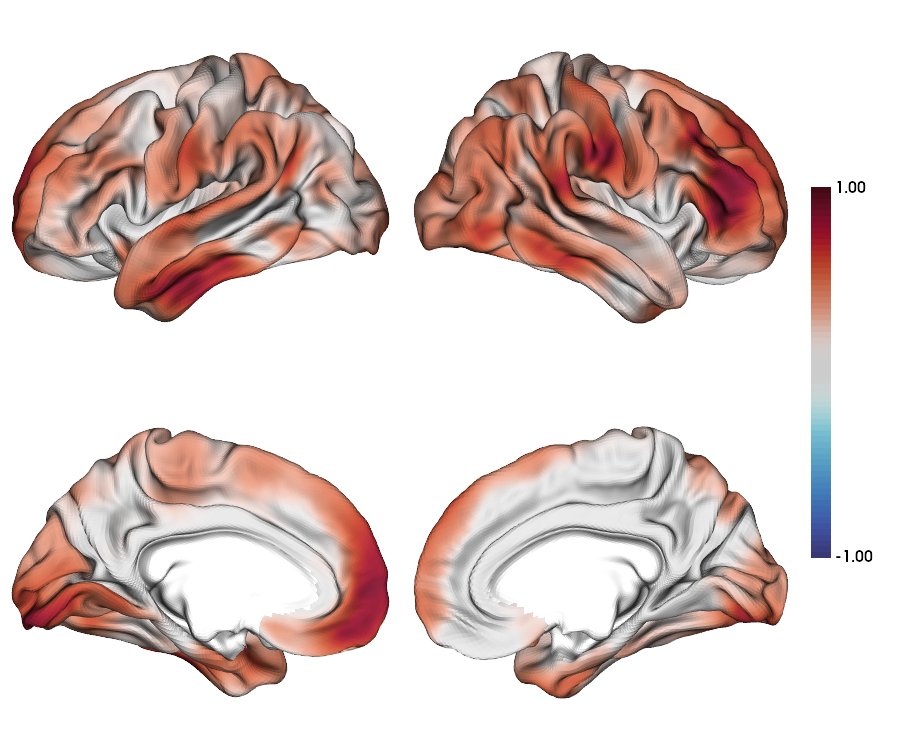

In [9]:
TLE_cohens_d = cohenD_gen_LR(TLE_surf, HC_surf)

TLE_cohens_d[TLE_cohens_d <0 ] = 0

plot_hemispheres(pial_left, pial_right,TLE_cohens_d,
                color_bar=True,
                embed_nb=True,
                transparent_bg=True,
                zoom=1.3,
                color_range=(-1,1),
                size=(900,750),
                nan_color=(1, 1, 1, 1),
                cmap=IceAmp,
                layout_style='grid', share='both')

In [30]:
df_TLE

,code,Dignosis,focus,age,sex,code_raulpaper,DX_code,diagnosis,comment
2,PX080,Left temporal plus /temporo-insular epilepsy s...,L,65,F,Y,TLE+,TLE+,NaN
5,PX152,possible TLE vs posterior quadrant epilepsy,R,28,F,Y,TLE+,TLE+,NaN
9,PX012,left temporal epilepsy,L,34,F,Y,TLE,TLE,NaN
10,PX017,left TLE secondary to complex malformation of ...,L,33,F,Y,TLE,TLE,NaN
11,PX020,left temporal epilepsy,L,52,M,Y,TLE,TLE,NaN
12,PX025,"right TLE, lesional FCD vs low grade glioma of...",R,25,M,Y,TLE,TLE,NaN
13,PX036,temporal epilepsy with deep generator,L,25,M,Y,TLE,TLE,NaN
14,PX044,right TLE possibly due to right mesial tempora...,R,44,M,Y,TLE,TLE,NaN
15,PX050,right temporal lobe epilepsy,R,32,M,Y,TLE,TLE,NaN
16,PX060,"right mesiotemporal lobe epilepsy , non lesional",R,25,F,Y,TLE,TLE,NaN


In [31]:
print(f"mean age: {df_TLE.age.mean()}")
print(f"std age: {df_TLE.age.std()}")
print(f"# M: {np.sum(df_TLE.sex == 'M')}")
print(f"# F: {np.sum(df_TLE.sex == 'F')}")

mean age: 36.6551724137931
std age: 11.991889705930914
# M: 15
# F: 14


## modeling

In [32]:
cols = ["code","age","sex"]

df_HC_TLE = pd.concat([
    df_HC[cols].assign(group='HC'),
    df_TLE[cols].assign(group='TLE')
], ignore_index=True)
df_HC_TLE

HC_TLE_surf = np.vstack((
    HC_surf,
    TLE_surf
))

In [34]:
from brainstat.stats.terms import FixedEffect
pial_combined = fetch_template_surface("fslr32k", join=True)

term_age = FixedEffect(df_HC_TLE.age)
term_sex = FixedEffect(df_HC_TLE.sex)
term_group = FixedEffect(df_HC_TLE.group)

model = term_age + term_sex + term_group

In [14]:
print(model)

    intercept  age  sex_F  sex_M  group_HC  group_TLE
0           1   36      0      1         1          0
1           1   29      0      1         1          0
2           1   34      1      0         1          0
3           1   58      0      1         1          0
4           1   34      0      1         1          0
..        ...  ...    ...    ...       ...        ...
63          1   35      0      1         0          1
64          1   68      0      1         0          1
65          1   29      1      0         0          1
66          1   39      0      1         0          1
67          1   49      1      0         0          1

[68 rows x 6 columns]


In [43]:
from brainstat.stats.SLM import SLM
contrast_group = (df_HC_TLE.group == "TLE").astype(int) - (df_HC_TLE.group == "HC").astype(int)

slm = SLM(
    model,
    contrast_group,
    surf=pial_combined,
    mask=mask,
    correction=["rft"],
    two_tailed=True,
    cluster_threshold=0.01,
)
slm.fit(HC_TLE_surf)

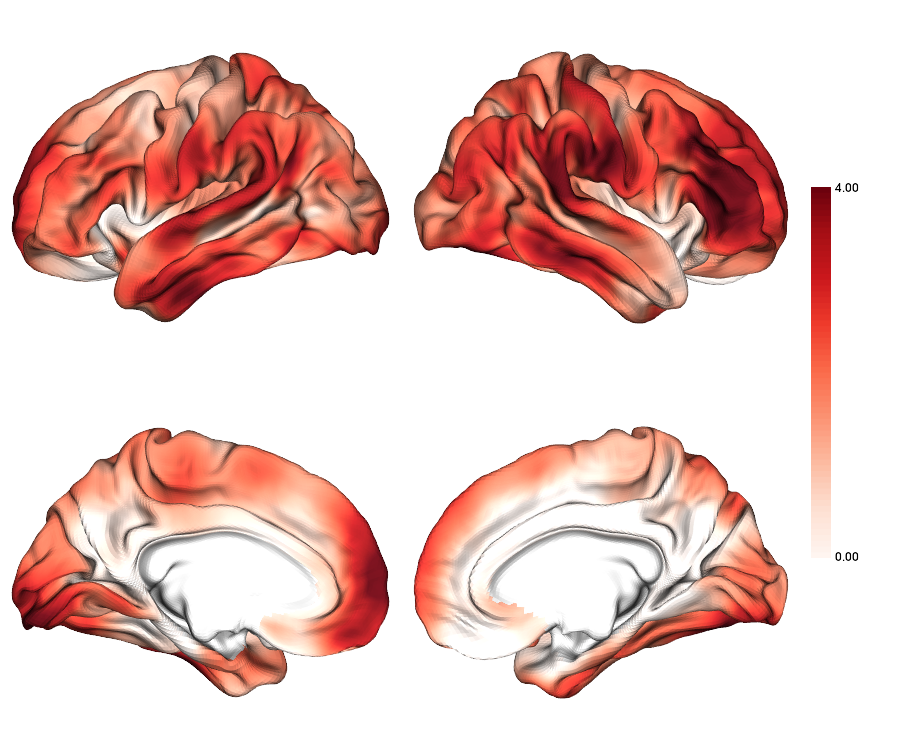

In [36]:
plot_hemispheres(pial_left, pial_right, slm.t, color_bar=True, color_range=(0, 4),
         cmap="Reds", embed_nb=True, size=(900, 750), zoom=1.3,
        nan_color=(1, 1, 1, 1), cb__labelTextProperty={"fontSize": 12}, interactive=False, layout_style='grid', share='both')

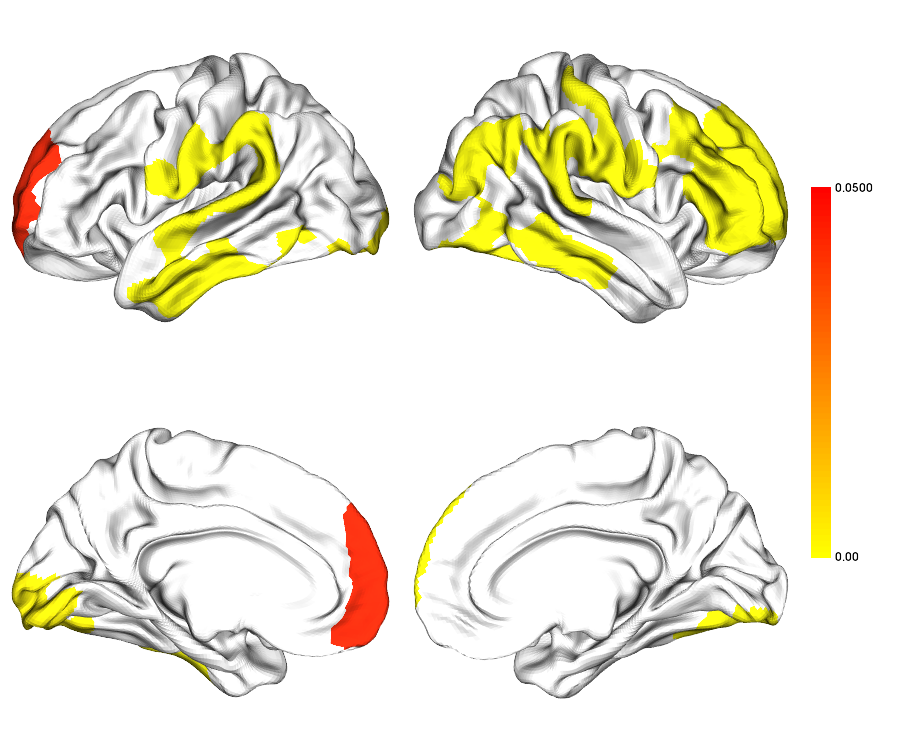

In [37]:
cp = [np.copy(slm.P["pval"]["C"])]
[np.place(x, np.logical_or(x > 0.05, ~mask), np.nan) for x in cp]

plot_hemispheres(pial_left, pial_right, cp[0].T, color_bar=True, color_range=(0, 0.05),
        cmap="autumn_r", embed_nb=True, size=(900, 750), 
        zoom=1.3, nan_color=(1, 1, 1, 1), cb__labelTextProperty={"fontSize": 12}, 
        interactive=False, layout_style='grid', share='both')

In [38]:
HC_all_mean = np.nanmean(HC_surf, axis=1)
TLE_all_mean = np.nanmean(TLE_surf, axis=1)


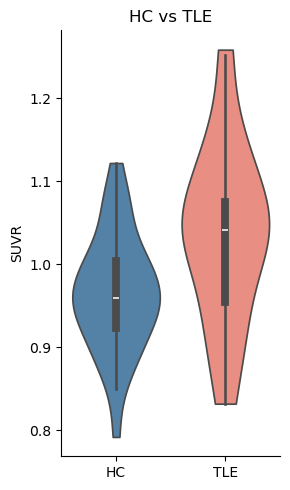

In [39]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_plot = pd.concat([
    pd.DataFrame({
        'Value': np.asarray(HC_all_mean).ravel(),
        'Group': 'HC'
    }),
    pd.DataFrame({
        'Value': np.asarray(TLE_all_mean).ravel(),
        'Group': 'TLE'
    })
], ignore_index=True)

# Remove NaN and infinite values
df_plot = df_plot.replace([np.inf, -np.inf], np.nan).dropna()

plt.figure(figsize=(3, 5))

sns.violinplot(
    data=df_plot,
    x='Group',
    y='Value',
    hue='Group',
    palette={'HC': 'steelblue', 'TLE': 'salmon'},
    inner='box',
    cut=0,
    legend=False
)

plt.ylabel('SUVR')
plt.xlabel('')
plt.title('HC vs TLE')
sns.despine()
plt.tight_layout()
plt.show()

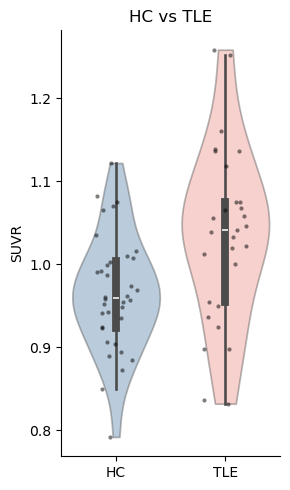

In [40]:
fig, ax = plt.subplots(figsize=(3, 5))

# Violin plot
sns.violinplot(
    data=df_plot,
    x='Group',
    y='Value',
    hue='Group',
    palette={'HC': 'steelblue', 'TLE': 'salmon'},
    inner='box',
    cut=0,
    alpha=0.4,
    legend=False,
    ax=ax
)

# Individual data points
sns.stripplot(
    data=df_plot,
    x='Group',
    y='Value',
    color='black',
    size=3,
    alpha=0.5,
    jitter=0.2,
    ax=ax
)

ax.set(xlabel='', ylabel='SUVR', title='HC vs TLE')
sns.despine()
plt.tight_layout()
plt.show()

In [48]:
from scipy.stats import ttest_ind
import numpy as np

# Mean SUVR per subject (assuming subjects × vertices)
# HC_values = np.nanmean(HC_all_mean, axis=1)
# TLE_values = np.nanmean(TLE_all_mean, axis=1)

# Welch's independent t-test
t_stat, p_value = ttest_ind(
    TLE_all_mean,
    HC_all_mean,
    equal_var=False,
    nan_policy='omit'
)

print(f"HC: {np.nanmean(HC_all_mean):.3f} ± {np.nanstd(HC_all_mean, ddof=1):.3f}")
print(f"TLE: {np.nanmean(TLE_all_mean):.3f} ± {np.nanstd(TLE_all_mean, ddof=1):.3f}")
print(f"t = {t_stat:.3f}, p = {p_value:.4g}")

HC: 0.965 ± 0.070
TLE: 1.036 ± 0.106
t = 3.101, p = 0.003279


In [47]:
print(slm.P["peak"])

[            t  vertid  clusid         P
0    4.896317   62175       1  0.004575
1    4.839924   41944       1  0.005484
2    4.597904   44160       1  0.011908
3    4.572349   44201       1  0.012893
4    4.436722   50945       1  0.019672
..        ...     ...     ...       ...
96   2.481607   44695      20  2.781023
97   2.480795   44791      20  2.785184
98   2.470120   30308      25  2.839900
99   2.466759   12093      19  2.857123
100  2.452293   48367      24  2.934060

[101 rows x 4 columns], Empty DataFrame
Columns: [t, vertid, clusid, P]
Index: []]


# Plot options

## RBV-FS

In [3]:
BIDS_FDG_HC = '/data/mica3/BIDS_CERMEP-MRXFDG'
T_FDG_HC = pd.read_csv('/data_/mica3/BIDS_CERMEP-MRXFDG/participants.csv')

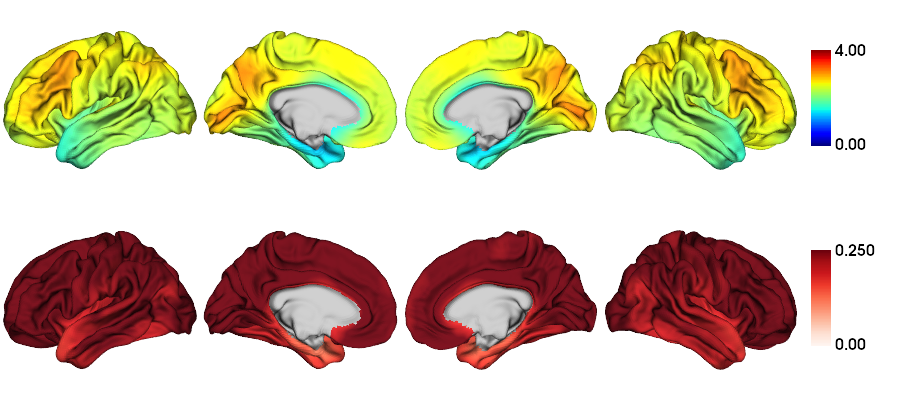

In [4]:
surf_L = []
surf_R = []
group = "HC"
trc = "FDG"
pvc = "RBV-FS"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.6_{pvc}_{ref}"

for subj in T_FDG_HC.participant_id:
    subj = subj.removeprefix("sub-")
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    
FDG_HC_L_surf = surf_L
FDG_HC_R_surf = surf_R

to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,color_range=[(0,4),(0,0.25)],size=(900,400),nan_color=(0.7, 0.7, 0.7, 1),cmap=["jet","Reds"])

In [5]:
save = np.hstack((surf_L,surf_R))

np.savetxt(f"/host/verges/tank/data/jack/micapet/resources/reference/referenceset_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.csv", save, delimiter=",")

In [18]:
# HC_surf-fsl32k_label-midthickness_pvc-RBV-FS_ref-pons_smooth-10mm_trc-FDG_pet 
HC_surf = np.hstack((surf_L, surf_R))

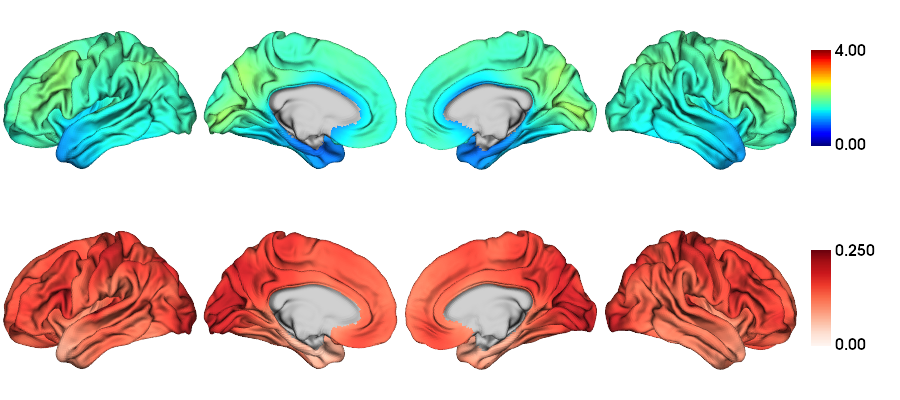

In [ ]:
surf_L = []
surf_R = []
group = "HC"
trc = "FDG"
pvc = "RBV-FS"
ref = "cerebellarGM"

MICA_PET_dir = f"{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.6_{pvc}_{ref}"

for subj in T_FDG_HC.participant_id:
    subj = subj.removeprefix("sub-")
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))


to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,color_range=[(0,4),(0,0.25)],size=(900,400),nan_color=(0.7, 0.7, 0.7, 1),cmap=["jet","Reds"])

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

pvc_methods = ["RBV-FS","IY","MG"]
ref_region = ["pons","cerebellarGM"]
# pvc_methods = ["MG"]
# ref_region = ["pons"]
pvc_data = {}

for pvc in pvc_methods:
    for ref in ref_region:
        surf_L = []
        surf_R = []
        group = "HC"
        trc = "FDG"

        MICA_PET_dir = f"{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.6_{pvc}_{ref}"

        for subj in T_FDG_HC.participant_id:
            subj = subj.removeprefix("sub-")
            L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-5k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
            R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-5k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
            surf_L.append(nilearn.surface.load_surf_data(L_file))
            surf_R.append(nilearn.surface.load_surf_data(R_file))
        
        # mean_std = mean_std_gen(surf_L,surf_R,mask)
        # mean = np.hstack((np.mean(surf_L, axis=0), np.mean(surf_R, axis=0)))
        all_data = np.hstack((np.array(surf_L), np.array(surf_R)))
        pvc_data[(pvc, ref)] = all_data

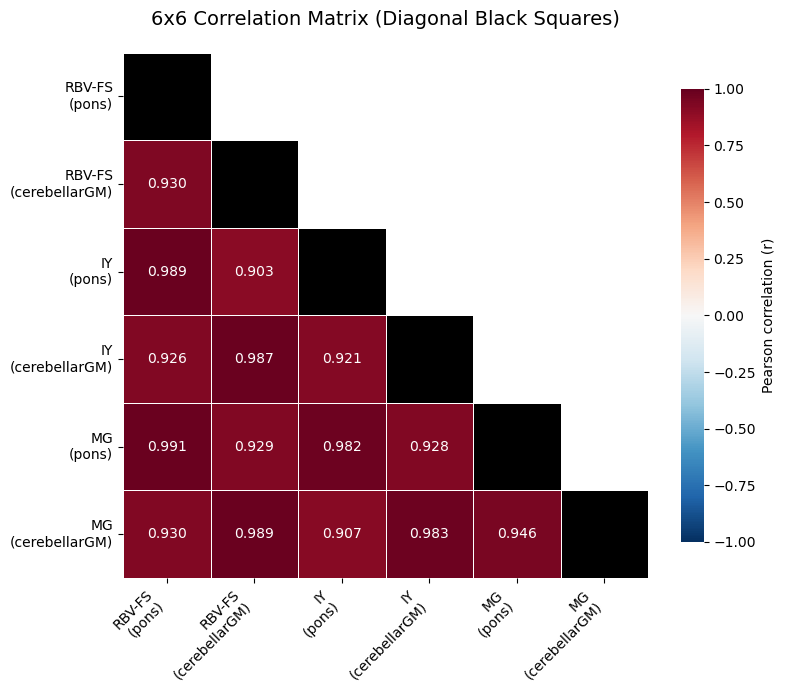

In [15]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. Create labels for each of the 6 combinations
labels = [f"{pvc}\n({ref})" for pvc, ref in pvc_data.keys()]

# 2. Flatten each (37, 64984) array into a 1D vector of 2,404,408 elements
flattened_data = {label: matrix.ravel() for label, matrix in zip(labels, pvc_data.values())}

# 3. Create a DataFrame where each column is one PVC/Ref condition
df = pd.DataFrame(flattened_data)

# 4. Compute the 6x6 Pearson correlation matrix
corr_matrix = df.corr()

# -------------------------------------------------------------------------
# 5. Create Separate Masks for the Heatmaps
# -------------------------------------------------------------------------
# Mask for the top half AND the diagonal (Strictly lower triangle elements)
lower_no_diag_mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=0)

# Mask for everything EXCEPT the diagonal
only_diag_mask = ~np.eye(corr_matrix.shape[0], dtype=bool)

# -------------------------------------------------------------------------
# 6. Plotting the Overlaid Heatmaps
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 7))

# Step A: Plot the lower triangle (excluding diagonal) with RdBu_r colormap
sns.heatmap(
    corr_matrix, 
    mask=lower_no_diag_mask,
    annot=True, 
    cmap='RdBu_r', 
    vmin=-1, vmax=1, 
    fmt=".3f", 
    square=True, 
    xticklabels=labels,      # <--- Explicitly set x-labels here
    yticklabels=labels,      # <--- Explicitly set y-labels here
    cbar_kws={"label": "Pearson correlation (r)", "shrink": 0.8},
    linewidths=.5,
    ax=ax
)

# Step B: Overlay solid black squares precisely on the diagonal elements
sns.heatmap(
    np.ones_like(corr_matrix), 
    mask=only_diag_mask,
    cmap=ListedColormap(['black']), 
    annot=False,            
    cbar=False,             
    square=True, 
    xticklabels=labels,      # <--- Keep labels consistent so they stay visible
    yticklabels=labels,      # <--- Keep labels consistent so they stay visible
    linewidths=.5,
    ax=ax
)

# -------------------------------------------------------------------------
# 7. Formatting Layout
# -------------------------------------------------------------------------
ax.set_title('6x6 Correlation Matrix (Diagonal Black Squares)', pad=20, fontsize=14)

# Apply rotation adjustments cleanly to the active axis
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig('pvc_correlation_black_diagonal.png', dpi=300)
plt.show()